<div style="background:linear-gradient(90deg,#373b44,#4286f4);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">Bayes' Theorem (1763)</h1>
<p style="margin:0">The mathematics of <b>changing your mind when you see evidence</b>.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | 1763 (published after his death) |
| **Inventor** | Reverend Thomas Bayes (English statistician and minister); published by Richard Price; developed independently by Pierre-Simon Laplace |
| **Family** | Probability → the foundation of **probabilistic AI** |
| **Learns from data?** | ✅ It *updates beliefs* when new evidence arrives |
| **Builds on** | Probability theory (Pascal and Fermat, 1654) |
| **Leads to** | Naive Bayes, Bayesian networks, spam filters, medical diagnosis |
| **Difficulty** | ⭐⭐ Beginner (just fractions and counting) |

### 🎯 What you will learn in this notebook
1. Why this 260-year-old formula is inside modern AI
2. The four parts: **prior, likelihood, evidence, posterior**
3. A medical test where the "obvious" answer is wrong (and Bayes fixes it)
4. How to **update beliefs again and again** as evidence arrives
5. Check the formula with a **simulation** and with **real data**
6. Solve the famous **Monty Hall** puzzle
7. Bayes' **own** problem: guessing a coin's bias, and watching belief sharpen

## 📖 Part 1: The story

**Thomas Bayes** (about 1701 to 1761) was an English minister who loved mathematics. He asked a question that turned probability upside down:

> Normal probability goes **cause → effect**: *"If a coin is fair, how likely are 7 heads in 10 flips?"*
> Bayes asked the **reverse**: *"I saw 7 heads in 10 flips. How likely is it that the coin is fair?"*

This is **inverse probability**, and it is exactly what **learning from data** means: you see effects (data) and want to reason back to causes (hypotheses).

Bayes never published his work. After he died in **1761**, his friend **Richard Price** found it, tidied it up and sent it to the Royal Society, which published it in **1763** as *"An Essay towards solving a Problem in the Doctrine of Chances"*.

### 🔭 What happened next
- **1774 and 1812:** the French mathematician **Laplace** independently discovered the same idea and developed it into a full theory.
- **1900s:** statisticians argued for decades about whether it was legitimate to use "prior beliefs" in science.
- **World War II:** Alan Turing and colleagues used Bayesian reasoning to rank Enigma codebreaking guesses.
- **1980s onward:** computers made Bayesian methods practical. Judea Pearl created **Bayesian networks** (1985).
- **Today:** spam filters, medical diagnosis, self-driving car sensors, recommendation systems and many machine learning methods use it.

### 🗺️ Where this fits
```
Bayes' Theorem (1763) → Least Squares (1805) → ... → Naive Bayes classifier (1960s) → Bayesian networks (1985)
```

## 🧠 Part 2: The idea in plain words

You believe something to some degree (your **prior**). Then you see **evidence**. Bayes' theorem tells you **exactly how much** to change your belief (your **posterior**).

> 🌧️ *You think there is a 30% chance of rain today. You then see dark clouds. How likely is rain now?* It depends on how often dark clouds appear **when it rains** compared to **when it doesn't**.

### ➗ The formula

$$P(A \mid B) = \frac{P(B \mid A)\; P(A)}{P(B)}$$

| Symbol | Name | Meaning |
|---|---|---|
| $P(A)$ | **Prior** | How likely is `A` *before* seeing the evidence? |
| $P(B \mid A)$ | **Likelihood** | If `A` is true, how likely is the evidence `B`? |
| $P(B)$ | **Evidence** | How likely is `B` overall? |
| $P(A \mid B)$ | **Posterior** | How likely is `A` *after* seeing `B`? |

The evidence is built from both possibilities (`A` true, or `A` false):

$$P(B) = P(B \mid A)\,P(A) + P(B \mid \text{not } A)\,P(\text{not } A)$$

> 💡 **Easy trick:** think in **counts**. Imagine 10,000 people, count how many fall into each group, and divide. That is all Bayes' theorem is.

## 🟣 Step 1: Import the libraries
> 💡 `numpy` for maths and random simulation, `pandas` for tables, `matplotlib` for charts, and `scikit-learn` just for a real dataset.

In [1]:
# Import the libraries we need
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_breast_cancer

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, NAVY, GREEN, ORANGE, RED, PURPLE, GREY, DARK = "#4286f4", "#373b44", "#27ae60", "#f39c12", "#e74c3c", "#8e54e9", "#bdc3c7", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🏥 Step 2: The medical test puzzle
> 💡 A disease affects **1%** of people. A test is **95% sensitive** (it detects 95% of sick people) and has a **5% false-positive rate** (5% of healthy people also test positive).
>
> You test **positive**. What is the chance you are actually sick?
>
> Most people say "about 95%". Let's use Bayes and see.

In [2]:
# Bayes' theorem applied to the medical test
prior = 0.01             # P(sick)
sensitivity = 0.95       # P(positive | sick)
false_positive = 0.05    # P(positive | healthy)

# Evidence: how likely is a positive test overall?
p_positive = sensitivity * prior + false_positive * (1 - prior)

# Posterior: P(sick | positive)
posterior = sensitivity * prior / p_positive

steps = pd.DataFrame({
    "step": ["Prior P(sick)", "Likelihood P(positive | sick)", "P(positive | healthy)",
             "Evidence P(positive)", "Posterior P(sick | positive)"],
    "value": [prior, sensitivity, false_positive, round(p_positive, 4), round(posterior, 4)]
})
print(steps.to_string(index=False))
print(f"\n👉 After a positive test you are sick with probability {posterior:.1%}, NOT 95%!")

                         step  value
                Prior P(sick)  0.010
Likelihood P(positive | sick)  0.950
        P(positive | healthy)  0.050
         Evidence P(positive)  0.059
 Posterior P(sick | positive)  0.161

👉 After a positive test you are sick with probability 16.1%, NOT 95%!


## 👥 Step 3: See it with 10,000 people
> 💡 Why only 16%? Imagine **10,000 people**:
> - 🔴 Sick and positive: **95**
> - 🟠 Sick but the test missed them: **5**
> - 🟣 Healthy but positive (false alarms): **495**
> - ⚪ Healthy and negative: **9,405**
>
> The picture shows **only the people who test positive**, one square each. Among everyone who tests positive (🔴 + 🟣), most are 🟣, because there are **so many more healthy people** that even a small false-positive rate creates a lot of false alarms.

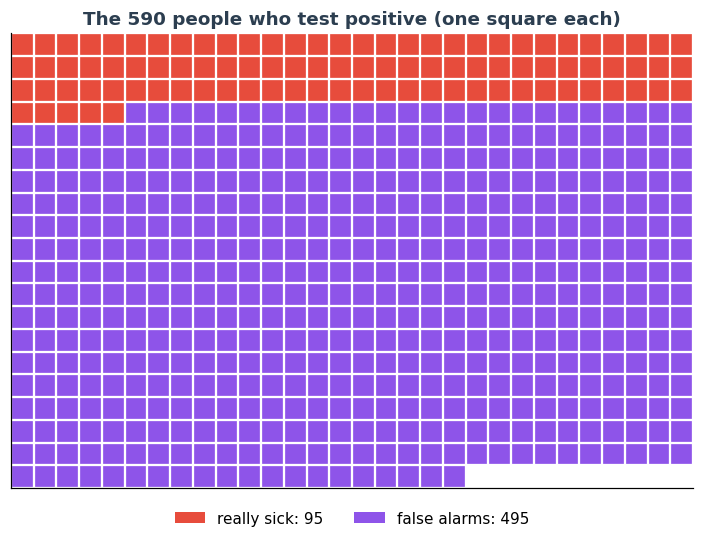

Out of 10,000 people: 95 sick+positive, 5 sick+negative, 495 healthy+positive, 9,405 healthy+negative
Positives in total: 95 + 495 = 590
Of those, truly sick: 95 / 590 = 16.1%


In [3]:
# Count 10,000 people, then draw everyone who tested positive as a "waffle" of squares
population = 10_000
sick = round(population * prior)                                     # 100
sick_pos = round(sick * sensitivity)                                 # 95
sick_neg = sick - sick_pos                                           # 5
healthy = population - sick                                          # 9,900
healthy_pos = round(healthy * false_positive)                        # 495
healthy_neg = healthy - healthy_pos                                  # 9,405

positives = sick_pos + healthy_pos                                   # 590 squares
cols, rows_n = 30, 20
waffle = np.full(cols * rows_n, np.nan)
waffle[:sick_pos] = 0                                                # 95 truly sick
waffle[sick_pos:positives] = 1                                       # 495 false alarms
waffle = waffle.reshape(rows_n, cols)

fig, ax = plt.subplots(figsize=(8, 5.6))
ax.imshow(np.ma.masked_invalid(waffle), cmap=ListedColormap([RED, PURPLE]), interpolation="nearest")
for x in np.arange(-0.5, cols, 1):
    ax.axvline(x, color="white", lw=1.5)
for y in np.arange(-0.5, rows_n, 1):
    ax.axhline(y, color="white", lw=1.5)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"The {positives} people who test positive (one square each)", color=DARK, fontweight="bold")
ax.bar(0, 0, color=RED, label=f"really sick: {sick_pos}")
ax.bar(0, 0, color=PURPLE, label=f"false alarms: {healthy_pos}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.show()

print(f"Out of {population:,} people: {sick_pos} sick+positive, {sick_neg} sick+negative, "
      f"{healthy_pos} healthy+positive, {healthy_neg:,} healthy+negative")
print(f"Positives in total: {sick_pos} + {healthy_pos} = {positives}")
print(f"Of those, truly sick: {sick_pos} / {positives} = {sick_pos / positives:.1%}")

## 🎲 Step 4: Does the formula really work? Simulate it
> 💡 A good habit: **test a formula with a simulation**. We create **1,000,000 random people** following the same rules, keep only those who tested positive, and count how many are really sick.
> If Bayes is right, the result should be close to 16.1%.

In [4]:
# Monte Carlo simulation of the medical test
rng = np.random.default_rng(42)
N = 1_000_000

is_sick = rng.random(N) < prior
tests_positive = np.where(is_sick, rng.random(N) < sensitivity, rng.random(N) < false_positive)

simulated = is_sick[tests_positive].mean()
print(f"People tested positive:      {tests_positive.sum():,}")
print(f"Of those, really sick:       {simulated:.2%}   (simulation)")
print(f"Bayes' theorem predicted:    {posterior:.2%}")
assert abs(simulated - posterior) < 0.01
print("✅ The simulation agrees with the formula!")

People tested positive:      59,204
Of those, really sick:       16.06%   (simulation)
Bayes' theorem predicted:    16.10%
✅ The simulation agrees with the formula!


## 📈 Step 5: The prior matters a lot
> 💡 The *same* test gives very different answers depending on **how common the disease is** (the prior). This is the most important lesson in the whole subject.
> The chart shows the posterior probability for four different tests. Even an excellent test (99% sensitive, 1% false alarms) gives a modest answer for rare diseases.

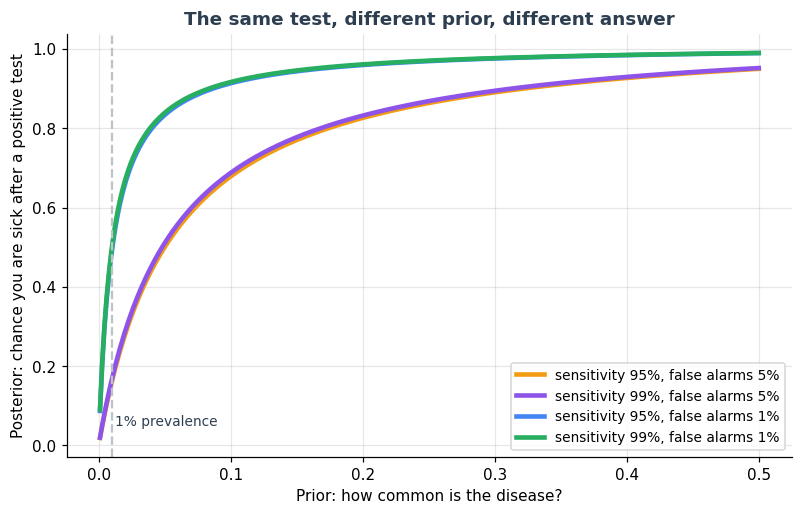

In [5]:
# Posterior as a function of the prior, for four different tests
def bayes_posterior(prior, sensitivity, false_positive):
    evidence = sensitivity * prior + false_positive * (1 - prior)
    return sensitivity * prior / evidence

priors = np.linspace(0.001, 0.5, 300)
tests = [("sensitivity 95%, false alarms 5%", 0.95, 0.05, ORANGE),
         ("sensitivity 99%, false alarms 5%", 0.99, 0.05, PURPLE),
         ("sensitivity 95%, false alarms 1%", 0.95, 0.01, BLUE),
         ("sensitivity 99%, false alarms 1%", 0.99, 0.01, GREEN)]

plt.figure(figsize=(8.5, 5))
for label, se, fp, color in tests:
    plt.plot(priors, [bayes_posterior(p, se, fp) for p in priors], lw=3, color=color, label=label)
plt.axvline(0.01, color=GREY, ls="--"); plt.text(0.012, 0.05, "1% prevalence", color=DARK, fontsize=9)
plt.xlabel("Prior: how common is the disease?")
plt.ylabel("Posterior: chance you are sick after a positive test")
plt.title("The same test, different prior, different answer", color=DARK, fontweight="bold")
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.show()

## 🔁 Step 6: Learning step by step
> 💡 What if you take the test **again** and it's positive again? Bayes' theorem is built for this: **yesterday's posterior becomes today's prior**.
> (We assume the tests are independent of each other.)

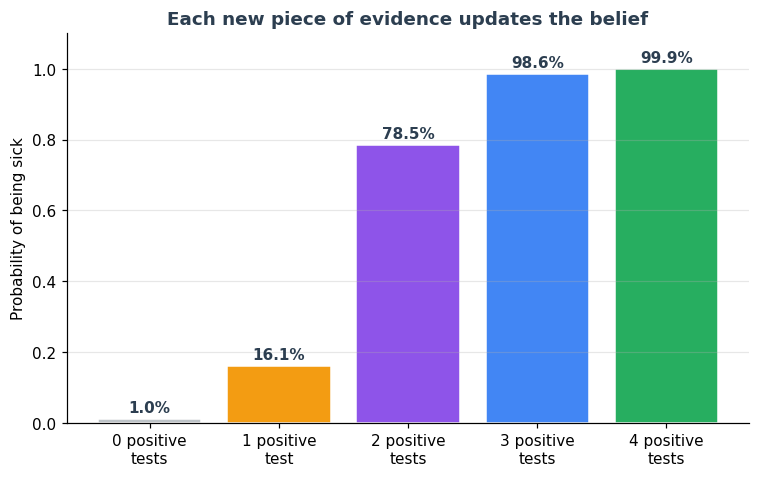

In [6]:
# Sequential updating: yesterday's posterior becomes today's prior
belief = prior
history = [belief]
for test_number in range(1, 5):
    belief = bayes_posterior(belief, sensitivity, false_positive)
    history.append(belief)

plt.figure(figsize=(8, 4.6))
bars = plt.bar([f"{k} positive\ntests" if k != 1 else "1 positive\ntest" for k in range(5)], history,
               color=[GREY, ORANGE, PURPLE, BLUE, GREEN], edgecolor="white")
for bar, v in zip(bars, history):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.1%}", ha="center", fontweight="bold", color=DARK)
plt.ylim(0, 1.1); plt.ylabel("Probability of being sick")
plt.title("Each new piece of evidence updates the belief", color=DARK, fontweight="bold")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🔬 Step 7: Bayes with real data
> 💡 scikit-learn has a real dataset: **569 breast-tissue samples**, labelled **malignant** or **benign**.
> Question: *"A sample has a large cell radius (mean radius above 15). How likely is it to be malignant?"*
> We answer it **two ways**: with Bayes' formula (prior, likelihood, evidence) and by directly counting. They must match, because Bayes' theorem *is* counting.

Prior         P(malignant)                = 0.373
Likelihood    P(large radius | malignant) = 0.759
Likelihood    P(large radius | benign)    = 0.034
Evidence      P(large radius)             = 0.304

Bayes' formula:  P(malignant | large radius) = 0.931
Direct counting: P(malignant | large radius) = 0.931


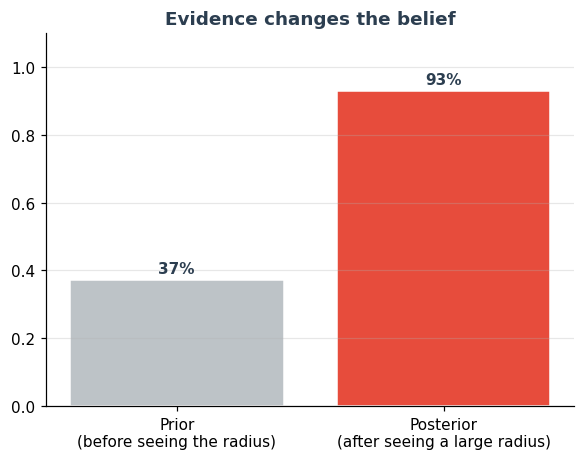

In [7]:
# Real data: P(malignant | large radius)
data = load_breast_cancer(as_frame=True)
df = data.frame
df["malignant"] = (df["target"] == 0)                      # in this dataset 0 = malignant
df["large_radius"] = df["mean radius"] > 15

p_malignant = df["malignant"].mean()                                        # prior
p_large_given_malignant = df.loc[df["malignant"], "large_radius"].mean()    # likelihood
p_large_given_benign = df.loc[~df["malignant"], "large_radius"].mean()
p_large = p_large_given_malignant * p_malignant + p_large_given_benign * (1 - p_malignant)   # evidence

bayes_answer = p_large_given_malignant * p_malignant / p_large
counting_answer = df.loc[df["large_radius"], "malignant"].mean()            # just count!

print(f"Prior         P(malignant)                = {p_malignant:.3f}")
print(f"Likelihood    P(large radius | malignant) = {p_large_given_malignant:.3f}")
print(f"Likelihood    P(large radius | benign)    = {p_large_given_benign:.3f}")
print(f"Evidence      P(large radius)             = {p_large:.3f}")
print(f"\nBayes' formula:  P(malignant | large radius) = {bayes_answer:.3f}")
print(f"Direct counting: P(malignant | large radius) = {counting_answer:.3f}")
assert abs(bayes_answer - counting_answer) < 1e-9

plt.figure(figsize=(6.2, 4.4))
plt.bar(["Prior\n(before seeing the radius)", "Posterior\n(after seeing a large radius)"], [p_malignant, bayes_answer],
        color=[GREY, RED], edgecolor="white")
for i, v in enumerate([p_malignant, bayes_answer]):
    plt.text(i, v + 0.02, f"{v:.0%}", ha="center", fontweight="bold", color=DARK)
plt.ylim(0, 1.1); plt.title("Evidence changes the belief", color=DARK, fontweight="bold")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🚪 Step 8: The Monty Hall puzzle
> 💡 A game show: **3 doors**, a car behind one, goats behind the other two. You pick a door (say door 1). The host, who **knows** where the car is, opens a *different* door that hides a **goat** (say door 3). He asks: *"Do you want to switch to door 2?"*
>
> Should you switch? Many people (even mathematicians) say "it's 50-50". Bayes says **switching wins 2 out of 3 times**. Let's check with a simulation of 100,000 games.

In [8]:
# Monty Hall simulation
def play(switch, rng):
    car = rng.randrange(3)
    pick = rng.randrange(3)
    # the host opens a door that is neither your pick nor the car
    host = rng.choice([d for d in range(3) if d != pick and d != car])
    if switch:
        pick = next(d for d in range(3) if d != pick and d != host)
    return pick == car

rng_py = random.Random(7)
games = 100_000
win_stay = sum(play(False, rng_py) for _ in range(games)) / games
win_switch = sum(play(True, rng_py) for _ in range(games)) / games
print(f"Stay with your first door: wins {win_stay:.1%}")
print(f"Switch doors:              wins {win_switch:.1%}")

# The same answer with Bayes' theorem:
# Hypotheses: car is behind door 1, 2 or 3 (prior 1/3 each). Evidence: host opens door 3 after you picked door 1.
likelihood = {1: 1 / 2,      # car behind 1: host may open door 2 or 3, picks 3 half the time
              2: 1.0,        # car behind 2: host MUST open door 3
              3: 0.0}        # car behind 3: host cannot open door 3
evidence = sum(likelihood[d] * (1 / 3) for d in likelihood)
print("\nBayes' posterior for each door after the host opens door 3:")
for d in (1, 2, 3):
    print(f"  car behind door {d}: {likelihood[d] * (1 / 3) / evidence:.3f}")

Stay with your first door: wins 33.2%
Switch doors:              wins 66.6%

Bayes' posterior for each door after the host opens door 3:
  car behind door 1: 0.333
  car behind door 2: 0.667
  car behind door 3: 0.000


## 🪙 Step 9: Bayes' own problem: guess the coin
> 💡 This is close to the problem Bayes actually solved. A coin lands heads with an **unknown probability `p`**. We start knowing **nothing** (every value of `p` equally likely). After each flip we update our belief about `p`.
>
> With `h` heads and `t` tails, the updated belief (the **posterior**) is a smooth curve called the **Beta distribution**, `Beta(1 + h, 1 + t)`, with the **average** `(1 + h) / (2 + h + t)`.
> Watch the curve become **narrower and narrower** around the true value (here, `p = 0.7`) as evidence piles up.

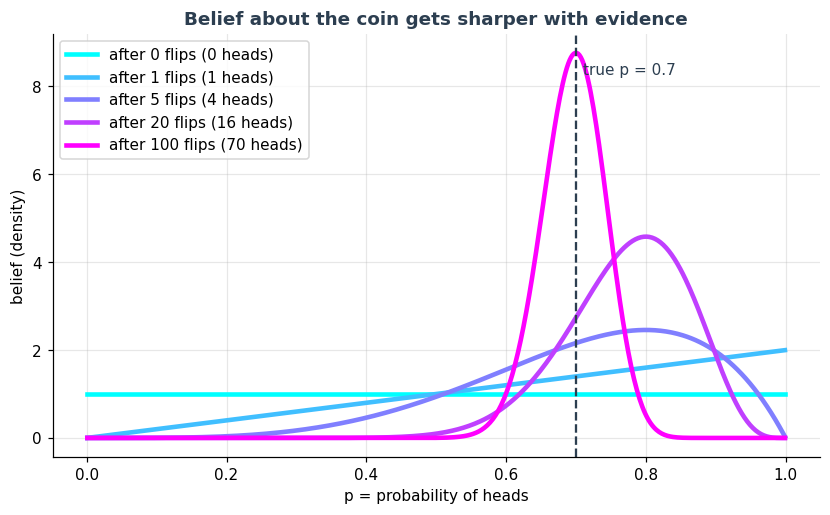

 flips  heads  tails  posterior mean
     0      0      0           0.500
     1      1      0           0.667
     5      4      1           0.714
    20     16      4           0.773
   100     70     30           0.696


In [9]:
# Belief about the coin's bias after more and more flips
def beta_pdf(x, a, b):
    log_norm = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    return np.exp(log_norm + (a - 1) * np.log(x) + (b - 1) * np.log(1 - x))

rng = np.random.default_rng(3)
true_p = 0.7
flips = rng.random(100) < true_p                      # True = heads
x = np.linspace(0.001, 0.999, 500)

plt.figure(figsize=(9, 5))
colors = plt.cm.cool(np.linspace(0, 1, 5))
rows = []
for n, color in zip([0, 1, 5, 20, 100], colors):
    heads = int(flips[:n].sum()); tails = n - heads
    a, b = 1 + heads, 1 + tails
    plt.plot(x, beta_pdf(x, a, b), lw=3, color=color, label=f"after {n} flips ({heads} heads)")
    rows.append({"flips": n, "heads": heads, "tails": tails, "posterior mean": round(a / (a + b), 3)})
plt.axvline(true_p, color=DARK, ls="--", lw=1.5)
plt.text(true_p + 0.01, plt.ylim()[1] * 0.9, "true p = 0.7", color=DARK)
plt.xlabel("p = probability of heads"); plt.ylabel("belief (density)")
plt.title("Belief about the coin gets sharper with evidence", color=DARK, fontweight="bold")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

## ✉️ Step 10: A spam filter teaser
> 💡 Spam filters are Bayes' theorem applied to words. Suppose **40%** of email is spam. The word **"free"** appears in **60%** of spam but only **5%** of normal email ("ham").
> An email contains "free". How likely is it spam?
>
> (With many words together, we will need an extra trick, the "naive" assumption. That is the **Naive Bayes** classifier, a story for later.)

In [10]:
# One-word spam filter
p_spam = 0.40
p_free_given_spam = 0.60
p_free_given_ham = 0.05

p_free = p_free_given_spam * p_spam + p_free_given_ham * (1 - p_spam)
p_spam_given_free = p_free_given_spam * p_spam / p_free
print(f"P(spam | contains 'free') = {p_spam_given_free:.1%}")

P(spam | contains 'free') = 88.9%


## ⚠️ Limitations of Bayes' theorem

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **The prior is a judgement call** | Two people can start with different priors and reach different answers (with little data) | More data washes the prior out; sensitivity analysis |
| ❌ **Hard with many variables** | Exact calculation explodes when many things depend on each other | Naive Bayes (assumes independence), Bayesian networks (1985), MCMC sampling |
| ❌ **Needs the likelihoods** | You must know `P(evidence | hypothesis)` | Learn them from data |
| ❌ **Humans are bad at it** | People ignore base rates (the *base-rate fallacy*) | Use natural frequencies, like the 10,000-people grid |

### 🧬 What it gave us
- A principled rule for **learning from evidence**
- The mindset of **uncertainty as probability**, central to modern AI
- The base for **Naive Bayes, Bayesian networks, Kalman filters and Bayesian optimization**

## 📝 Summary
1. ✅ Bayes' theorem **reverses** conditional probability: from effects back to causes.
2. ✅ **Posterior ∝ likelihood × prior.** Never forget the prior (how common is it?).
3. ✅ A positive test for a rare disease is usually a **false alarm**, because healthy people vastly outnumber sick ones.
4. ✅ **Yesterday's posterior is today's prior**, so beliefs update step by step.
5. ✅ It is just **counting**: we checked with a simulation and with real data.

## 🧪 Practice time
**Exercise 1.** Use the same test (95% sensitivity, 5% false alarms) but a disease that affects only **0.1%** of people. What is the posterior now?

**Exercise 2.** Monty Hall with **100 doors**: you pick one, the host opens **98** goat doors. Simulate the chance of winning if you switch.

**Exercise 3.** A coin gives **7 heads and 3 tails**. Starting from no knowledge, what is the posterior mean of `p`? Compare it with the plain ratio `7/10`.

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1
print(bayes_posterior(0.001, 0.95, 0.05))        # about 0.019 (1.9%): a rarer disease means even more false alarms

# Exercise 2
def monty_100(switch, rng):
    car, pick = rng.randrange(100), rng.randrange(100)
    if switch:
        return pick != car        # host removes 98 goats, so switching wins whenever your first pick was wrong
    return pick == car
rng2 = random.Random(0)
print(sum(monty_100(True, rng2) for _ in range(100_000)) / 100_000)     # about 0.99

# Exercise 3
h, t = 7, 3
print((1 + h) / (2 + h + t))      # 0.667: slightly pulled toward 0.5 by the "no knowledge" prior
```
</details>

## ⏭️ What's next in AI-Genesis
Next stops on the road: **Gradient Descent (Cauchy, 1847)**, the engine that later trains neural networks. 🚀